Name : Mukesh Gupta
Roll no : 2500320310079

# Movie Ratings and Box-Office Analysis
**P10 – Jupyter Notebook**

This notebook analyzes the `movies_metadata.csv` dataset for the Movie Ratings and Box-Office Analysis project. It uses Python for data cleaning, exploratory analysis, numerical comparisons, and report generation. The results can later be used to create the Power BI dashboard.

**Project tools:** Excel, Python, Power BI  
**Data source:** The Movies Dataset – `movies_metadata.csv`  
**Important:** The notebook calculates results from the CSV when it is run. It does not invent missing results. Some findings recorded in the project discussion are included as checks, but the current dataset and notebook output should be treated as the final evidence.

## 1. Import libraries
**What:** Import the Python libraries used for data handling, numerical calculations, and charts.  
**Why:** Pandas is used to read and clean the CSV, NumPy supports calculations, and Matplotlib/Seaborn create visual summaries.

In [1]:
from pathlib import Path
import ast
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Find the project folder and load the raw dataset
**What:** Search the current folder and its parent folders for `data/raw/movies_metadata.csv`.  
**Why:** This makes the notebook work whether it is saved in the project root, a `notebooks` folder, or a `src` folder. Keep the original CSV in `data/raw/`.

In [2]:
current = Path.cwd().resolve()
candidates = [current, *current.parents]
project_root = None

for folder in candidates:
    if (folder / "data" / "raw" / "movies_metadata.csv").exists():
        project_root = folder
        break

if project_root is None:
    # Also allow the CSV to be in the same folder as the notebook.
    local_csv = current / "movies_metadata.csv"
    if local_csv.exists():
        project_root = current
        raw_file = local_csv
    else:
        raise FileNotFoundError(
            "Could not find data/raw/movies_metadata.csv. "
            "Place movies_metadata.csv inside the project's data/raw folder."
        )
else:
    raw_file = project_root / "data" / "raw" / "movies_metadata.csv"

clean_dir = project_root / "data" / "clean"
reports_dir = project_root / "reports"
clean_dir.mkdir(parents=True, exist_ok=True)
reports_dir.mkdir(parents=True, exist_ok=True)

print("Project folder:", project_root)
print("Raw dataset:", raw_file)
print("Clean output folder:", clean_dir)
print("Reports folder:", reports_dir)

raw_df = pd.read_csv(raw_file, low_memory=False)
print("Dataset shape:", raw_df.shape)
display(raw_df.head())

Project folder: C:\Movie_Ratings_and_Box-Office_Analysis__2500320310079_Mukesh_Gupta
Raw dataset: C:\Movie_Ratings_and_Box-Office_Analysis__2500320310079_Mukesh_Gupta\data\raw\movies_metadata.csv
Clean output folder: C:\Movie_Ratings_and_Box-Office_Analysis__2500320310079_Mukesh_Gupta\data\clean
Reports folder: C:\Movie_Ratings_and_Box-Office_Analysis__2500320310079_Mukesh_Gupta\reports
Dataset shape: (45466, 24)


,adult,belongs_to_collection,budget,genres,homepage,id,imdb_id,original_language,original_title,overview,popularity,poster_path,production_companies,production_countries,release_date,revenue,runtime,spoken_languages,status,tagline,title,video,vote_average,vote_count
0,False,"{'id': 10194, 'name': 'Toy Story Collection', ...",30000000,"[{'id': 16, 'name': 'Animation'}, {'id': 35, '...",http://toystory.disney.com/toy-story,862,tt0114709,en,Toy Story,"Led by Woody, Andy's toys live happily in his ...",21.946943,/rhIRbceoE9lR4veEXuwCC2wARtG.jpg,"[{'name': 'Pixar Animation Studios', 'id': 3}]","[{'iso_3166_1': 'US', 'name': 'United States o...",1995-10-30,"373,554,033.00",81.00,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,NaN,Toy Story,False,7.70,"5,415.00"
1,False,NaN,65000000,"[{'id': 12, 'name': 'Adventure'}, {'id': 14, '...",NaN,8844,tt0113497,en,Jumanji,When siblings Judy and Peter discover an encha...,17.015539,/vzmL6fP7aPKNKPRTFnZmiUfciyV.jpg,"[{'name': 'TriStar Pictures', 'id': 559}, {'na...","[{'iso_3166_1': 'US', 'name': 'United States o...",1995-12-15,"262,797,249.00",104.00,"[{'iso_639_1': 'en', 'name': 'English'}, {'iso...",Released,Roll the dice and unleash the excitement!,Jumanji,False,6.90,"2,413.00"
2,False,"{'id': 119050, 'name': 'Grumpy Old Men Collect...",0,"[{'id': 10749, 'name': 'Romance'}, {'id': 35, ...",NaN,15602,tt0113228,en,Grumpier Old Men,A family wedding reignites the ancient feud be...,11.7129,/6ksm1sjKMFLbO7UY2i6G1ju9SML.jpg,"[{'name': 'Warner Bros.', 'id': 6194}, {'name'...","[{'iso_3166_1': 'US', 'name': 'United States o...",1995-12-22,0.00,101.00,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Still Yelling. Still Fighting. Still Ready for...,Grumpier Old Men,False,6.50,92.00
3,False,NaN,16000000,"[{'id': 35, 'name': 'Comedy'}, {'id': 18, 'nam...",NaN,31357,tt0114885,en,Waiting to Exhale,"Cheated on, mistreated and stepped on, the wom...",3.859495,/16XOMpEaLWkrcPqSQqhTmeJuqQl.jpg,[{'name': 'Twentieth Century Fox Film Corporat...,"[{'iso_3166_1': 'US', 'name': 'United States o...",1995-12-22,"81,452,156.00",127.00,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Friends are the people who let you be yourself...,Waiting to Exhale,False,6.10,34.00
4,False,"{'id': 96871, 'name': 'Father of the Bride Col...",0,"[{'id': 35, 'name': 'Comedy'}]",NaN,11862,tt0113041,en,Father of the Bride Part II,Just when George Banks has recovered from his ...,8.387519,/e64sOI48hQXyru7naBFyssKFxVd.jpg,"[{'name': 'Sandollar Productions', 'id': 5842}...","[{'iso_3166_1': 'US', 'name': 'United States o...",1995-02-10,"76,578,911.00",106.00,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Just When His World Is Back To Normal... He's ...,Father of the Bride Part II,False,5.70,173.00


## 3. Inspect the dataset
**What:** Review column names, data types, missing values, and basic statistics.  
**Why:** Inspection helps identify fields that need conversion or cleaning before calculating ratings, revenue, profit, and genre summaries.

In [3]:
print("Column names:")
print(raw_df.columns.tolist())

print("\nData types and non-null counts:")
raw_df.info()

print("\nMissing values (top 15 columns):")
display(raw_df.isna().sum().sort_values(ascending=False).head(15).to_frame("missing_count"))

print("\nNumerical summary:")
display(raw_df.describe(include="all").T)

Column names:
['adult', 'belongs_to_collection', 'budget', 'genres', 'homepage', 'id', 'imdb_id', 'original_language', 'original_title', 'overview', 'popularity', 'poster_path', 'production_companies', 'production_countries', 'release_date', 'revenue', 'runtime', 'spoken_languages', 'status', 'tagline', 'title', 'video', 'vote_average', 'vote_count']

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 45466 entries, 0 to 45465
Data columns (total 24 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   adult                  45466 non-null  str    
 1   belongs_to_collection  4494 non-null   str    
 2   budget                 45466 non-null  str    
 3   genres                 45466 non-null  str    
 4   homepage               7782 non-null   str    
 5   id                     45466 non-null  str    
 6   imdb_id                45449 non-null  str    
 7   original_language      45455 non-null  str 

,missing_count
belongs_to_collection,40972
homepage,37684
tagline,25054
overview,954
poster_path,386
runtime,263
status,87
release_date,87
imdb_id,17
original_language,11



Numerical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
adult,45466,5,False,45454,NaN,NaN,NaN,NaN,NaN,NaN,NaN
belongs_to_collection,4494,1698,"{'id': 415931, 'name': 'The Bowery Boys', 'pos...",29,NaN,NaN,NaN,NaN,NaN,NaN,NaN
budget,45466,1226,0,36573,NaN,NaN,NaN,NaN,NaN,NaN,NaN
genres,45466,4069,"[{'id': 18, 'name': 'Drama'}]",5000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
homepage,7782,7673,http://www.georgecarlin.com,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
id,45466,45436,141971,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
imdb_id,45449,45417,tt1180333,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
original_language,45455,92,en,32269,NaN,NaN,NaN,NaN,NaN,NaN,NaN
original_title,45466,43373,Alice in Wonderland,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
overview,44512,44307,No overview found.,133,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Select and prepare the analysis columns
**What:** Keep the fields needed for this project and convert budget, revenue, rating, votes, runtime, and release date into usable types.  
**Why:** Consistent data types prevent calculation errors and make the analysis easier to reproduce.

In [4]:
required = [
    "id", "title", "genres", "budget", "revenue", "release_date",
    "runtime", "original_language", "status", "vote_average", "vote_count"
]
missing_columns = [c for c in required if c not in raw_df.columns]
if missing_columns:
    raise ValueError(f"Required columns are missing from the CSV: {missing_columns}")

df = raw_df[required].copy()
df["id"] = df["id"].astype(str).str.strip()
df["title"] = df["title"].astype("string").str.strip()
for col in ["budget", "revenue", "runtime", "vote_average", "vote_count"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")
df["release_date"] = pd.to_datetime(df["release_date"], errors="coerce")
df["release_year"] = df["release_date"].dt.year

print("Prepared dataset shape:", df.shape)
display(df.head())

Prepared dataset shape: (45466, 12)


,id,title,genres,budget,revenue,release_date,runtime,original_language,status,vote_average,vote_count,release_year
0,862,Toy Story,"[{'id': 16, 'name': 'Animation'}, {'id': 35, '...","30,000,000.00","373,554,033.00",1995-10-30,81.00,en,Released,7.70,"5,415.00","1,995.00"
1,8844,Jumanji,"[{'id': 12, 'name': 'Adventure'}, {'id': 14, '...","65,000,000.00","262,797,249.00",1995-12-15,104.00,en,Released,6.90,"2,413.00","1,995.00"
2,15602,Grumpier Old Men,"[{'id': 10749, 'name': 'Romance'}, {'id': 35, ...",0.00,0.00,1995-12-22,101.00,en,Released,6.50,92.00,"1,995.00"
3,31357,Waiting to Exhale,"[{'id': 35, 'name': 'Comedy'}, {'id': 18, 'nam...","16,000,000.00","81,452,156.00",1995-12-22,127.00,en,Released,6.10,34.00,"1,995.00"
4,11862,Father of the Bride Part II,"[{'id': 35, 'name': 'Comedy'}]",0.00,"76,578,911.00",1995-02-10,106.00,en,Released,5.70,173.00,"1,995.00"


## 5. Remove invalid IDs and duplicate movies
**What:** Remove blank or non-numeric movie IDs, then keep only the first row for each movie ID.  
**Why:** A movie should appear once in the movie-level table. Duplicate IDs can inflate counts and distort averages and totals.

In [5]:
before_id = len(df)
df = df[df["id"].str.fullmatch(r"\d+", na=False)].copy()
invalid_id_rows = before_id - len(df)

before_duplicates = len(df)
df = df.drop_duplicates(subset="id", keep="first").copy()
duplicate_rows = before_duplicates - len(df)

print(f"Rows removed for invalid IDs: {invalid_id_rows:,}")
print(f"Duplicate movie rows removed: {duplicate_rows:,}")
print(f"Rows remaining: {len(df):,}")

Rows removed for invalid IDs: 3
Duplicate movie rows removed: 30
Rows remaining: 45,433


## 6. Handle missing and invalid numeric values
**What:** Treat zero or implausibly small budgets/revenues as unavailable, invalidate impossible ratings and runtimes, and flag ratings with fewer than 10 votes as less reliable.  
**Why:** Profit and ROI need meaningful budget and revenue values. Rating analysis should also distinguish low-vote records from ratings supported by a larger number of votes.

**Project rule:** Movies with missing budgets remain available for rating analysis, but are excluded from profit and ROI calculations. Zero revenue is treated as missing for revenue averages unless separately verified as a genuine release outcome.

In [6]:
quality_counts = {}

quality_counts["budget_zero"] = int((df["budget"] == 0).sum())
quality_counts["revenue_zero"] = int((df["revenue"] == 0).sum())
quality_counts["budget_below_1000"] = int(((df["budget"] > 0) & (df["budget"] < 1000)).sum())
quality_counts["revenue_below_1000"] = int(((df["revenue"] > 0) & (df["revenue"] < 1000)).sum())
quality_counts["rating_zero_with_zero_votes"] = int(((df["vote_average"] == 0) & (df["vote_count"] == 0)).sum())
quality_counts["runtime_invalid"] = int(((df["runtime"] <= 0) | (df["runtime"] > 600)).sum())

df.loc[df["budget"] <= 0, "budget"] = np.nan
df.loc[df["revenue"] <= 0, "revenue"] = np.nan
df.loc[df["budget"] < 1000, "budget"] = np.nan
df.loc[df["revenue"] < 1000, "revenue"] = np.nan
df.loc[~df["vote_average"].between(0, 10), "vote_average"] = np.nan
df.loc[(df["vote_average"] == 0) & (df["vote_count"].fillna(0) == 0), "vote_average"] = np.nan
df.loc[(df["runtime"] <= 0) | (df["runtime"] > 600), "runtime"] = np.nan
df.loc[df["vote_count"] < 0, "vote_count"] = np.nan

df["reliable_rating"] = df["vote_count"].fillna(0) >= 10

print("Invalid-value counts detected before correction:")
display(pd.Series(quality_counts, name="rows").to_frame())
print("Missing values after correction:")
display(df.isna().sum().to_frame("missing_count"))

Invalid-value counts detected before correction:


,rows
budget_zero,36553
revenue_zero,38032
budget_below_1000,244
revenue_below_1000,154
rating_zero_with_zero_votes,2896
runtime_invalid,1574


Missing values after correction:


,missing_count
id,0
title,3
genres,0
budget,36797
revenue,38189
release_date,87
runtime,1834
original_language,11
status,84
vote_average,2899


## 7. Filter movie release status and prepare genres
**What:** Keep movies marked as `Released`, fill missing genre information with `Unknown`, and parse the genre field into a list of genre names.  
**Why:** Unreleased records may not have comparable box-office outcomes. A separate movie-to-genre table allows a movie to belong to more than one genre without duplicating the movie-level record.

In [7]:
status_before = len(df)
df["status"] = df["status"].astype("string").str.strip().str.lower()
df = df[df["status"] == "released"].copy()
status_removed = status_before - len(df)

def parse_genres(value):
    if pd.isna(value) or str(value).strip() == "":
        return ["Unknown"]
    try:
        parsed = ast.literal_eval(value) if isinstance(value, str) else value
        if isinstance(parsed, list):
            names = [str(item.get("name", "")).strip() for item in parsed
                     if isinstance(item, dict) and item.get("name")]
            return names if names else ["Unknown"]
    except (ValueError, SyntaxError, TypeError):
        pass
    return ["Unknown"]

df["genre_list"] = df["genres"].apply(parse_genres)
df["genre_list"] = df["genre_list"].apply(
    lambda items: list(dict.fromkeys(
        " ".join(name.split()).title() for name in items if name.strip()
    )) or ["Unknown"]
)

print(f"Unreleased/non-released rows removed: {status_removed:,}")
print("Movies remaining:", f"{len(df):,}")
display(df[["id", "title", "genre_list"]].head())

Unreleased/non-released rows removed: 448
Movies remaining: 44,985


,id,title,genre_list
0,862,Toy Story,"[Animation, Comedy, Family]"
1,8844,Jumanji,"[Adventure, Fantasy, Family]"
2,15602,Grumpier Old Men,"[Romance, Comedy]"
3,31357,Waiting to Exhale,"[Comedy, Drama, Romance]"
4,11862,Father of the Bride Part II,[Comedy]


## 8. Create movie-level and movie-genre tables
**What:** Create a clean movie table with one row per movie and a bridge table with one row per movie–genre relationship.  
**Why:** This design handles multiple genres correctly. Genre totals can overlap because one movie may belong to several genres; therefore, genre totals must not be added together.

In [8]:
movies = df.drop(columns=["genres", "genre_list"]).copy()
movie_genres = (
    df[["id", "genre_list"]]
    .explode("genre_list")
    .rename(columns={"id": "movie_id", "genre_list": "genre"})
    .drop_duplicates()
    .reset_index(drop=True)
)

print("Movie table:", movies.shape)
print("Movie-genre table:", movie_genres.shape)
print("Unique movie IDs:", movies["id"].nunique())
print("Unique genres:", movie_genres["genre"].nunique())
display(movie_genres.head(10))

Movie table: (44985, 12)
Movie-genre table: (92628, 2)
Unique movie IDs: 44985
Unique genres: 21


,movie_id,genre
0,862,Animation
1,862,Comedy
2,862,Family
3,8844,Adventure
4,8844,Fantasy
5,8844,Family
6,15602,Romance
7,15602,Comedy
8,31357,Comedy
9,31357,Drama


## 9. Calculate profit and return on investment (ROI)
**What:** Calculate profit as revenue minus budget, and ROI as profit divided by budget.  
**Why:** Profit and ROI compare financial performance more meaningfully than revenue alone. These calculations are made only where both budget and revenue are available.

In [9]:
movies["profit_usd"] = movies["revenue"] - movies["budget"]
movies["roi"] = np.where(
    movies["budget"].notna() & (movies["budget"] > 0) & movies["revenue"].notna(),
    movies["profit_usd"] / movies["budget"],
    np.nan
)

financial_movies = movies.dropna(subset=["budget", "revenue"]).copy()
print("Movies with both budget and revenue:", f"{len(financial_movies):,}")
print("Movies available for rating analysis:", f"{movies['vote_average'].notna().sum():,}")
display(financial_movies[["title", "budget", "revenue", "profit_usd", "roi"]].head())

Movies with both budget and revenue: 5,303
Movies available for rating analysis: 42,145


,title,budget,revenue,profit_usd,roi
0,Toy Story,"30,000,000.00","373,554,033.00","343,554,033.00",11.45
1,Jumanji,"65,000,000.00","262,797,249.00","197,797,249.00",3.04
3,Waiting to Exhale,"16,000,000.00","81,452,156.00","65,452,156.00",4.09
5,Heat,"60,000,000.00","187,436,818.00","127,436,818.00",2.12
8,Sudden Death,"35,000,000.00","64,350,171.00","29,350,171.00",0.84


## 10. Build the data-quality report
**What:** Summarize key cleaning actions and remaining data-quality information in a report.  
**Why:** A documented quality report makes the analysis transparent and helps explain why some records are excluded from particular calculations.

In [10]:
quality_report = pd.DataFrame([
    ["Invalid/non-numeric movie IDs removed", invalid_id_rows],
    ["Duplicate movie IDs removed", duplicate_rows],
    ["Non-released rows removed", status_removed],
    ["Zero budgets detected", quality_counts["budget_zero"]],
    ["Zero revenues detected", quality_counts["revenue_zero"]],
    ["Budgets below $1,000 detected", quality_counts["budget_below_1000"]],
    ["Revenues below $1,000 detected", quality_counts["revenue_below_1000"]],
    ["Zero rating with zero votes detected", quality_counts["rating_zero_with_zero_votes"]],
    ["Invalid runtimes detected", quality_counts["runtime_invalid"]],
    ["Clean movie rows", len(movies)],
    ["Movie-genre links", len(movie_genres)],
    ["Movies with budget and revenue", len(financial_movies)]
], columns=["data_quality_check", "count"])

display(quality_report)
quality_report.to_csv(reports_dir / "data_quality_log.csv", index=False)

,data_quality_check,count
0,Invalid/non-numeric movie IDs removed,3
1,Duplicate movie IDs removed,30
2,Non-released rows removed,448
3,Zero budgets detected,36553
4,Zero revenues detected,38032
5,"Budgets below $1,000 detected",244
6,"Revenues below $1,000 detected",154
7,Zero rating with zero votes detected,2896
8,Invalid runtimes detected,1574
9,Clean movie rows,44985


## 11. Answer business question 1: Which genres have the highest average rating and revenue?
**What:** Join the genre bridge table to movie records and calculate average rating and average revenue for each genre.  
**Why:** This identifies genres that perform well with audiences and genres that generate higher box-office revenue.

**Note:** A movie with multiple genres appears in each applicable genre group. Genre-level counts and totals therefore overlap.

In [11]:
genre_analysis = movie_genres.merge(
    movies[["id", "vote_average", "revenue", "reliable_rating"]],
    left_on="movie_id", right_on="id", how="left"
)

genre_summary = (
    genre_analysis.groupby("genre", dropna=False)
    .agg(
        movie_count=("movie_id", "nunique"),
        average_rating=("vote_average", "mean"),
        average_revenue_usd=("revenue", "mean"),
        reliable_rating_count=("reliable_rating", "sum")
    )
    .reset_index()
    .sort_values("average_revenue_usd", ascending=False)
)

display(genre_summary)
genre_summary.to_csv(reports_dir / "genre_summary.csv", index=False)

top_rating_genres = genre_summary.dropna(subset=["average_rating"]).nlargest(5, "average_rating")
top_revenue_genres = genre_summary.dropna(subset=["average_revenue_usd"]).nlargest(5, "average_revenue_usd")
print("Top genres by average rating:")
display(top_rating_genres[["genre", "average_rating", "movie_count"]])
print("Top genres by average revenue:")
display(top_revenue_genres[["genre", "average_revenue_usd", "movie_count"]])

,genre,movie_count,average_rating,average_revenue_usd,reliable_rating_count
1,Adventure,3468,5.88,"181,140,097.76",2402
2,Animation,1912,6.45,"179,343,005.70",1302
8,Fantasy,2290,5.93,"167,074,199.17",1551
7,Family,2740,5.93,"160,775,943.01",1772
15,Science Fiction,3013,5.48,"132,226,973.52",2062
0,Action,6542,5.75,"117,908,692.58",4322
16,Thriller,7566,5.74,"70,502,472.04",5109
19,War,1317,6.29,"66,570,953.77",704
3,Comedy,13073,5.97,"65,455,095.45",7598
13,Mystery,2453,5.96,"64,004,810.85",1533


Top genres by average rating:


,genre,average_rating,movie_count
5,Documentary,6.66,3872
2,Animation,6.45,1912
10,History,6.41,1391
12,Music,6.33,1587
19,War,6.29,1317


Top genres by average revenue:


,genre,average_revenue_usd,movie_count
1,Adventure,"181,140,097.76",3468
2,Animation,"179,343,005.70",1912
8,Fantasy,"167,074,199.17",2290
7,Family,"160,775,943.01",2740
15,Science Fiction,"132,226,973.52",3013


## 12. Visualize average rating and revenue by genre
**What:** Plot the five highest genres by average rating and average revenue.  
**Why:** Bar charts make it easier to compare genre performance and identify leading categories for the Power BI dashboard.

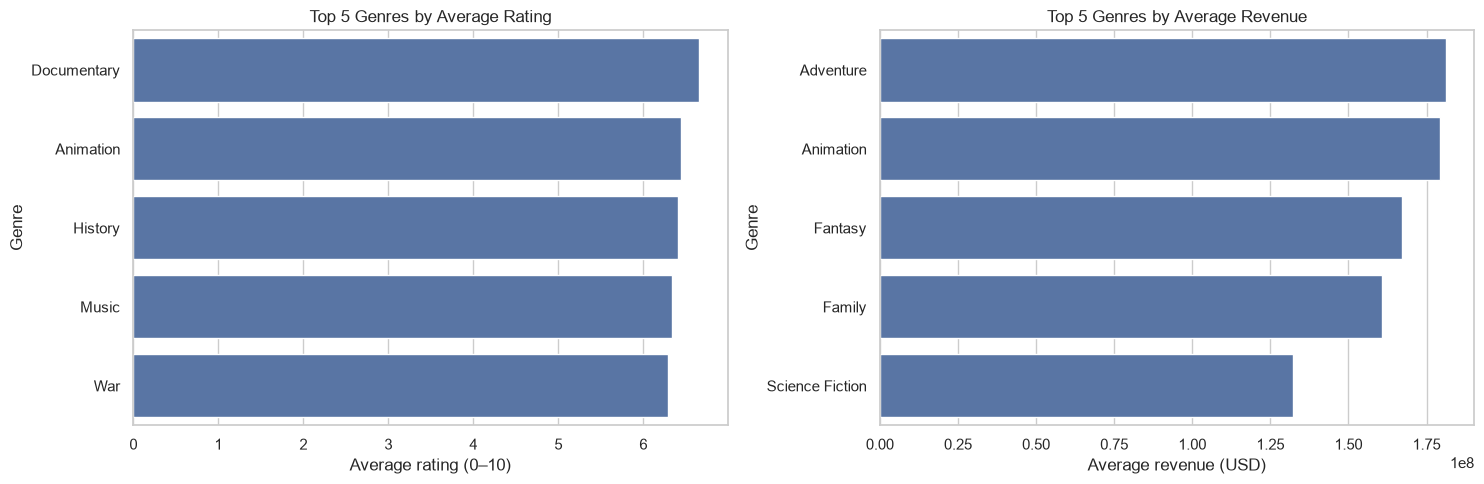

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

rating_plot = genre_summary.dropna(subset=["average_rating"]).nlargest(5, "average_rating")
sns.barplot(data=rating_plot, x="average_rating", y="genre", ax=axes[0])
axes[0].set_title("Top 5 Genres by Average Rating")
axes[0].set_xlabel("Average rating (0–10)")
axes[0].set_ylabel("Genre")

revenue_plot = genre_summary.dropna(subset=["average_revenue_usd"]).nlargest(5, "average_revenue_usd")
sns.barplot(data=revenue_plot, x="average_revenue_usd", y="genre", ax=axes[1])
axes[1].set_title("Top 5 Genres by Average Revenue")
axes[1].set_xlabel("Average revenue (USD)")
axes[1].set_ylabel("Genre")

plt.tight_layout()
plt.show()

## 13. Answer business question 2: Do higher-rated movies earn more revenue?
**What:** Calculate the Pearson correlation between rating and revenue, and display a scatter plot.  
**Why:** Correlation measures the strength and direction of a linear relationship. It does not prove that a higher rating causes higher revenue.

Rating–revenue Pearson correlation: 0.151
Movies included in this calculation: 7,205


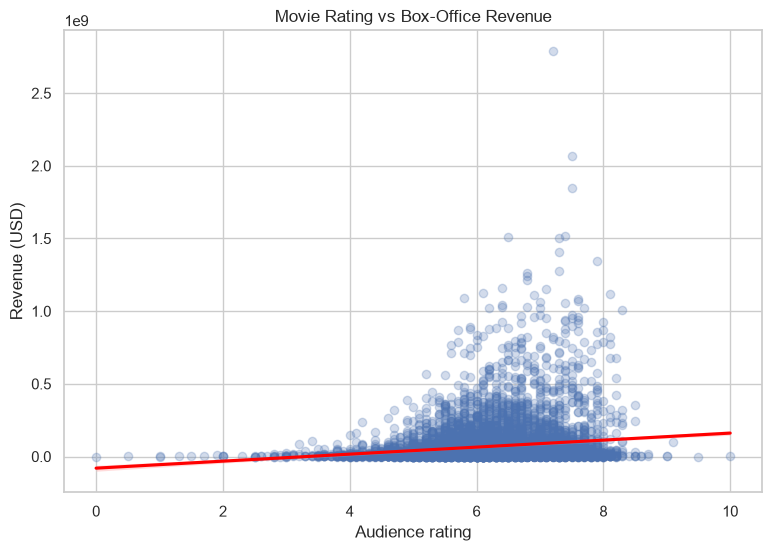

In [13]:
rating_revenue = movies.dropna(subset=["vote_average", "revenue"]).copy()
rating_revenue_corr = rating_revenue["vote_average"].corr(rating_revenue["revenue"])

print(f"Rating–revenue Pearson correlation: {rating_revenue_corr:.3f}")
print(f"Movies included in this calculation: {len(rating_revenue):,}")

plt.figure(figsize=(9, 6))
sns.regplot(
    data=rating_revenue, x="vote_average", y="revenue",
    scatter_kws={"alpha": 0.25}, line_kws={"color": "red"}
)
plt.title("Movie Rating vs Box-Office Revenue")
plt.xlabel("Audience rating")
plt.ylabel("Revenue (USD)")
plt.show()

## 14. Answer business question 3: Which 10 movies made the highest profit?
**What:** Sort movies with valid budget and revenue by profit and select the top 10.  
**Why:** Profit (revenue minus budget) highlights the movies with the largest absolute financial gain. This list is limited to records with both values available.

,id,title,release_year,budget,revenue,profit_usd,roi
0,19995,Avatar,"2,009.00","237,000,000.00","2,787,965,087.00","2,550,965,087.00",10.76
1,140607,Star Wars: The Force Awakens,"2,015.00","245,000,000.00","2,068,223,624.00","1,823,223,624.00",7.44
2,597,Titanic,"1,997.00","200,000,000.00","1,845,034,188.00","1,645,034,188.00",8.23
3,135397,Jurassic World,"2,015.00","150,000,000.00","1,513,528,810.00","1,363,528,810.00",9.09
4,168259,Furious 7,"2,015.00","190,000,000.00","1,506,249,360.00","1,316,249,360.00",6.93
5,24428,The Avengers,"2,012.00","220,000,000.00","1,519,557,910.00","1,299,557,910.00",5.91
6,12445,Harry Potter and the Deathly Hallows: Part 2,"2,011.00","125,000,000.00","1,342,000,000.00","1,217,000,000.00",9.74
7,99861,Avengers: Age of Ultron,"2,015.00","280,000,000.00","1,405,403,694.00","1,125,403,694.00",4.02
8,109445,Frozen,"2,013.00","150,000,000.00","1,274,219,009.00","1,124,219,009.00",7.49
9,321612,Beauty and the Beast,"2,017.00","160,000,000.00","1,262,886,337.00","1,102,886,337.00",6.89


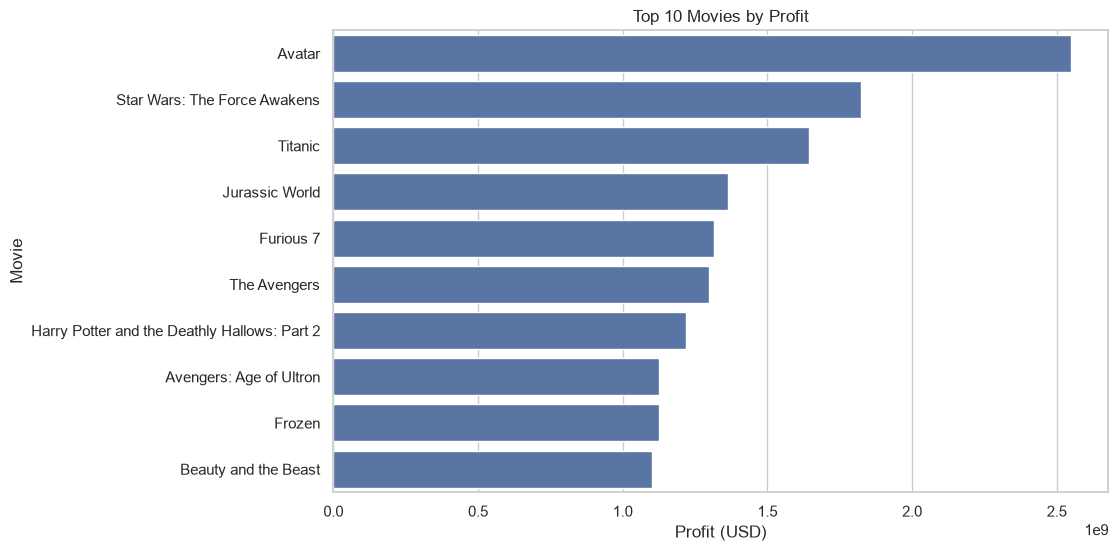

In [14]:
top10_profit = (
    financial_movies[["id", "title", "release_year", "budget", "revenue", "profit_usd", "roi"]]
    .sort_values("profit_usd", ascending=False)
    .head(10)
    .reset_index(drop=True)
)
display(top10_profit)
top10_profit.to_csv(reports_dir / "top10_profit.csv", index=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=top10_profit, x="profit_usd", y="title")
plt.title("Top 10 Movies by Profit")
plt.xlabel("Profit (USD)")
plt.ylabel("Movie")
plt.show()

## 15. Answer business question 4: Does a bigger budget lead to higher profit?
**What:** Calculate the correlation between budget and profit and compare budget/profit in a scatter plot.  
**Why:** This checks whether larger budgets are associated with higher profit in the available records. The result is an association, not proof that spending more causes greater profit.

Budget–profit Pearson correlation: 0.581
Movies included in this calculation: 5,303


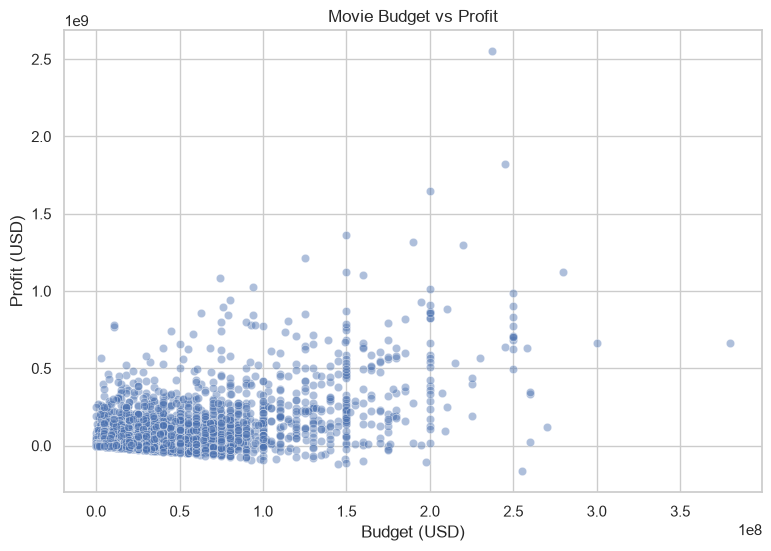

In [15]:
budget_profit = financial_movies.dropna(subset=["budget", "profit_usd"])
budget_profit_corr = budget_profit["budget"].corr(budget_profit["profit_usd"])

print(f"Budget–profit Pearson correlation: {budget_profit_corr:.3f}")
print(f"Movies included in this calculation: {len(budget_profit):,}")

plt.figure(figsize=(9, 6))
sns.scatterplot(data=budget_profit, x="budget", y="profit_usd", alpha=0.45)
plt.title("Movie Budget vs Profit")
plt.xlabel("Budget (USD)")
plt.ylabel("Profit (USD)")
plt.show()

## 16. Answer business question 5: How have ratings and box-office revenue changed over time?
**What:** Group movies by release year and calculate average rating and total revenue.  
**Why:** A year-wise trend shows how audience ratings and recorded box-office revenue change over time. Years with few usable records should be interpreted carefully.

,release_year,movie_count,average_rating,total_revenue_usd
118,"2,003.00",873,5.94,"15,767,126,016.00"
119,"2,004.00",980,6.01,"17,666,133,802.00"
120,"2,005.00",1114,5.88,"16,812,936,285.00"
121,"2,006.00",1259,5.92,"18,368,624,166.00"
122,"2,007.00",1313,5.93,"19,703,493,927.00"
123,"2,008.00",1457,5.86,"20,637,375,454.00"
124,"2,009.00",1574,5.90,"23,370,045,366.00"
125,"2,010.00",1477,5.92,"23,447,174,172.00"
126,"2,011.00",1644,5.89,"24,272,663,922.00"
127,"2,012.00",1707,5.92,"26,058,751,211.00"


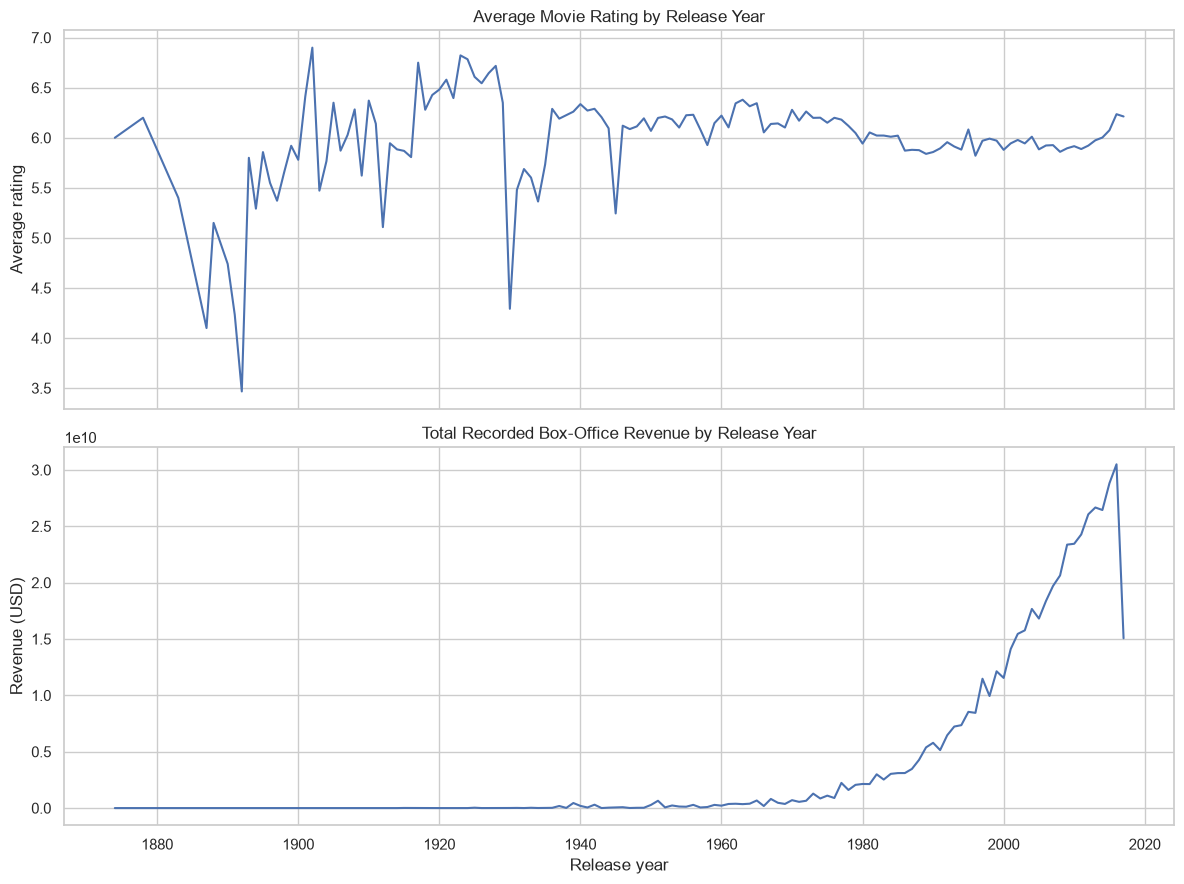

In [16]:
yearly_summary = (
    movies.dropna(subset=["release_year"])
    .groupby("release_year")
    .agg(
        movie_count=("id", "nunique"),
        average_rating=("vote_average", "mean"),
        total_revenue_usd=("revenue", "sum")
    )
    .reset_index()
    .sort_values("release_year")
)

display(yearly_summary.tail(15))
yearly_summary.to_csv(reports_dir / "yearly_summary.csv", index=False)

fig, axes = plt.subplots(2, 1, figsize=(12, 9), sharex=True)
sns.lineplot(data=yearly_summary, x="release_year", y="average_rating", ax=axes[0])
axes[0].set_title("Average Movie Rating by Release Year")
axes[0].set_ylabel("Average rating")

sns.lineplot(data=yearly_summary, x="release_year", y="total_revenue_usd", ax=axes[1])
axes[1].set_title("Total Recorded Box-Office Revenue by Release Year")
axes[1].set_ylabel("Revenue (USD)")
axes[1].set_xlabel("Release year")

plt.tight_layout()
plt.show()

## 17. Compare average ROI by genre
**What:** Calculate average ROI for each genre using only movies with valid budget and revenue.  
**Why:** ROI compares profit with the amount invested and can help identify genres that use budgets more efficiently. The result is based only on movies with both financial fields available.

,genre,movie_count,average_roi,average_profit_usd
13,Mystery,440,41.66,"46,171,265.95"
11,Horror,583,39.67,"34,643,897.97"
5,Documentary,55,15.65,"14,211,469.93"
10,History,234,12.36,"31,874,463.08"
17,Tv Movie,1,7.40,"37,000,000.00"
1,Adventure,950,5.81,"142,060,562.49"
2,Animation,290,5.80,"161,649,586.62"
16,Thriller,1487,5.21,"52,064,289.89"
12,Music,189,4.98,"47,434,862.82"
8,Fantasy,507,4.98,"137,784,041.62"


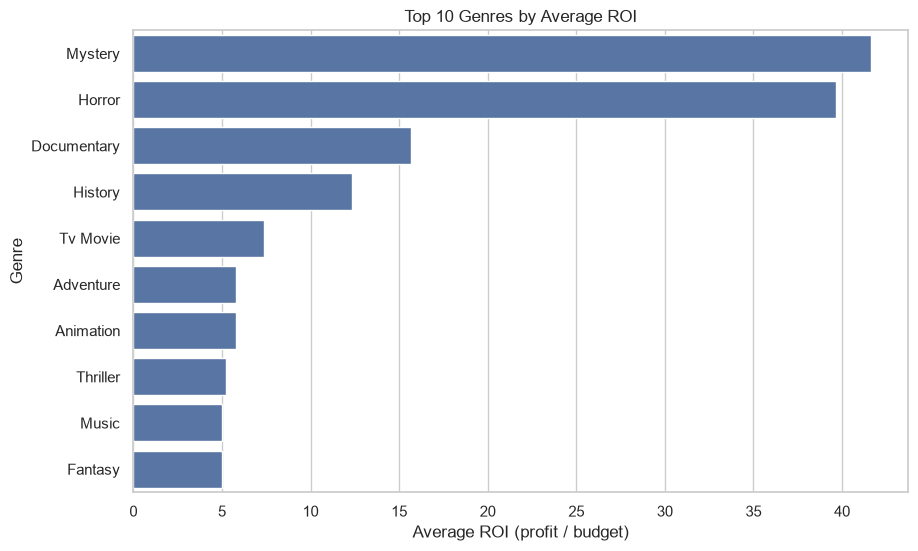

In [17]:
financial_genres = movie_genres.merge(
    financial_movies[["id", "budget", "revenue", "profit_usd", "roi"]],
    left_on="movie_id", right_on="id", how="inner"
)

roi_by_genre = (
    financial_genres.groupby("genre")
    .agg(
        movie_count=("movie_id", "nunique"),
        average_roi=("roi", "mean"),
        average_profit_usd=("profit_usd", "mean")
    )
    .reset_index()
    .sort_values("average_roi", ascending=False)
)

display(roi_by_genre)
roi_by_genre.to_csv(reports_dir / "genre_roi_summary.csv", index=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=roi_by_genre.head(10), x="average_roi", y="genre")
plt.title("Top 10 Genres by Average ROI")
plt.xlabel("Average ROI (profit / budget)")
plt.ylabel("Genre")
plt.show()

## 18. Export cleaned datasets for Excel and Power BI
**What:** Save the clean movie table and movie-to-genre table as CSV files.  
**Why:** These files can be opened in Excel or imported into Power BI. Keeping the movie table separate from the genre bridge table avoids duplicating movie-level facts.

In [18]:
movies.to_csv(clean_dir / "movies_clean.csv", index=False)
movie_genres.to_csv(clean_dir / "movie_genres.csv", index=False)

print("Files saved:")
print(clean_dir / "movies_clean.csv")
print(clean_dir / "movie_genres.csv")
print(reports_dir / "data_quality_log.csv")
print(reports_dir / "genre_summary.csv")
print(reports_dir / "genre_roi_summary.csv")
print(reports_dir / "yearly_summary.csv")
print(reports_dir / "top10_profit.csv")

Files saved:
C:\Movie_Ratings_and_Box-Office_Analysis__2500320310079_Mukesh_Gupta\data\clean\movies_clean.csv
C:\Movie_Ratings_and_Box-Office_Analysis__2500320310079_Mukesh_Gupta\data\clean\movie_genres.csv
C:\Movie_Ratings_and_Box-Office_Analysis__2500320310079_Mukesh_Gupta\reports\data_quality_log.csv
C:\Movie_Ratings_and_Box-Office_Analysis__2500320310079_Mukesh_Gupta\reports\genre_summary.csv
C:\Movie_Ratings_and_Box-Office_Analysis__2500320310079_Mukesh_Gupta\reports\genre_roi_summary.csv
C:\Movie_Ratings_and_Box-Office_Analysis__2500320310079_Mukesh_Gupta\reports\yearly_summary.csv
C:\Movie_Ratings_and_Box-Office_Analysis__2500320310079_Mukesh_Gupta\reports\top10_profit.csv


## 19. Validation checks
**What:** Check that movie IDs are unique, that the movie–genre table references existing movies, and that financial calculations are consistent.  
**Why:** Validation catches common data-processing mistakes before the results are used in Excel or Power BI.

In [19]:
checks = {
    "Movie IDs are unique": movies["id"].is_unique,
    "No blank movie IDs": movies["id"].notna().all() and (movies["id"].str.len() > 0).all(),
    "All genre links reference an existing movie": movie_genres["movie_id"].isin(movies["id"]).all(),
    "Profit equals revenue minus budget": np.allclose(
        financial_movies["profit_usd"],
        financial_movies["revenue"] - financial_movies["budget"],
        equal_nan=True
    ),
    "ROI is available only for valid financial records": financial_movies["roi"].notna().all()
}

for check, passed in checks.items():
    print(("PASS" if passed else "FAIL") + " - " + check)

assert all(checks.values()), "One or more validation checks failed."

PASS - Movie IDs are unique
PASS - No blank movie IDs
PASS - All genre links reference an existing movie
PASS - Profit equals revenue minus budget
PASS - ROI is available only for valid financial records


## 20. Final insights and recommendations
**What:** Generate a concise evidence-based summary from the calculated results.  
**Why:** The project should finish with conclusions supported by the actual dataset, not assumptions. The values below are calculated when the notebook runs, so they update if the input CSV changes.

### Key findings
The summary reports the cleaned movie count, the number of movies eligible for financial analysis, the strongest rating/revenue relationship, the top genres, and the highest-profit movie.

### Recommendations
- Use the genre rating and revenue summaries to build comparison visuals in Power BI.
- Show the top 10 profit table, but clearly state that it includes only movies with both budget and revenue.
- Add a note to the dashboard that multi-genre totals overlap and must not be summed across genres.
- Display the number of records behind each metric so viewers can judge how much data supports the result.
- Treat correlation as association, not causation.

In [20]:
# Create the final evidence-based summary using calculated values.
eligible_financial = len(financial_movies)
eligible_ratings = int(movies["vote_average"].notna().sum())
top_profit_row = top10_profit.iloc[0] if not top10_profit.empty else None
best_rating_genre = (
    genre_summary.dropna(subset=["average_rating"]).sort_values("average_rating", ascending=False).head(1)
)
best_revenue_genre = (
    genre_summary.dropna(subset=["average_revenue_usd"]).sort_values("average_revenue_usd", ascending=False).head(1)
)

print("FINAL PROJECT INSIGHTS")
print("----------------------")
print(f"Cleaned movie records: {len(movies):,}")
print(f"Movie-genre relationships: {len(movie_genres):,}")
print(f"Movies with usable ratings: {eligible_ratings:,}")
print(f"Movies with both budget and revenue: {eligible_financial:,}")
print(f"Rating–revenue correlation: {rating_revenue_corr:.3f}")
print(f"Budget–profit correlation: {budget_profit_corr:.3f}")

if not best_rating_genre.empty:
    r = best_rating_genre.iloc[0]
    print(f"Highest average rating genre: {r['genre']} ({r['average_rating']:.2f}/10)")
if not best_revenue_genre.empty:
    r = best_revenue_genre.iloc[0]
    print(f"Highest average revenue genre: {r['genre']} (${r['average_revenue_usd']:,.0f})")
if top_profit_row is not None:
    print(f"Highest-profit movie in the available records: {top_profit_row['title']} "
          f"(profit ${top_profit_row['profit_usd']:,.0f})")

print("\nRECOMMENDATIONS")
print("1. Build Power BI visuals from the exported genre, yearly, ROI, and top-10 reports.")
print("2. Clearly disclose the financial-analysis sample size:", f"{eligible_financial:,} movies.")
print("3. Explain that genre totals overlap because movies can have multiple genres.")
print("4. Do not interpret correlation as proof of cause and effect.")
print("5. Recheck the data-quality log after replacing or updating the source CSV.")

FINAL PROJECT INSIGHTS
----------------------
Cleaned movie records: 44,985
Movie-genre relationships: 92,628
Movies with usable ratings: 42,145
Movies with both budget and revenue: 5,303
Rating–revenue correlation: 0.151
Budget–profit correlation: 0.581
Highest average rating genre: Documentary (6.66/10)
Highest average revenue genre: Adventure ($181,140,098)
Highest-profit movie in the available records: Avatar (profit $2,550,965,087)

RECOMMENDATIONS
1. Build Power BI visuals from the exported genre, yearly, ROI, and top-10 reports.
2. Clearly disclose the financial-analysis sample size: 5,303 movies.
3. Explain that genre totals overlap because movies can have multiple genres.
4. Do not interpret correlation as proof of cause and effect.
5. Recheck the data-quality log after replacing or updating the source CSV.


## 21. Project conclusion
This notebook prepares the movie metadata for analysis, documents data-quality handling, answers the five business questions, and exports clean tables and summary reports for Excel and Power BI.

**Limitations to mention in the project report:**
- The dataset's release-year coverage and completeness depend on the supplied CSV.
- Budget and revenue are missing or recorded as zero for many movies, so financial conclusions use a smaller subset than rating analysis.
- Revenue and budget values are not adjusted for inflation or differences between currencies.
- A movie can belong to multiple genres, so genre-level counts and totals overlap.
- Correlation does not establish causation.

**Previously noted during the project discussion (verify by running this notebook on your exact CSV):** the earlier cleaning run reported 44,985 movies after cleaning, approximately 5,100 movies with budget, revenue, and at least 10 votes, and a source-year span of 1874–2020. Treat the freshly generated notebook outputs as authoritative if they differ.